# Optimisation différentiable sans contrainte — série d'exercices

**NJIFON GHANE MOUNIR** — SDIA 4, ENSPD (2026-2027)

Ce notebook résout les exercices du dossier `exercices/` (un fichier par exercice) avec nos propres
implémentations. Chaque algorithme est dans son propre fichier à la racine du dossier :
`gradient_pas_fixe.py`, `gradient_pas_optimal.py`, `gradient_conjugue.py`, `newton.py`, `quasi_newton.py`.
Les outils communs (algèbre linéaire, recherches linéaires, résultat) sont dans `outils/`.
Les algorithmes sont écrits à la main : pas de `scipy.optimize`, pas de `numpy.linalg`. Les systèmes linéaires sont
résolus par Gauss (pivot partiel) ou Cholesky, les valeurs propres par la méthode de Jacobi, et les recherches
linéaires (Armijo, Wolfe, section dorée) sont codées dans `outils/recherche_lineaire.py`.
`numpy` sert seulement à stocker les vecteurs, `sympy` à dériver f exactement (sinon : différences finies),
`matplotlib` seulement aux graphiques.

| Méthode | Direction $d_k$ | Pas $\alpha_k$ |
|---|---|---|
| Gradient à pas fixe | $-\nabla f(x_k)$ | constant ($0<\alpha<2/\lambda_{\max}$) |
| Gradient à pas optimal | $-\nabla f(x_k)$ | $\arg\min_{\alpha>0} f(x_k+\alpha d_k)$ (section dorée) |
| Gradient conjugué (Polak-Ribière+) | $-\nabla f(x_{k}) + \beta_{k} d_{k-1}$ | pas optimal |
| Newton | $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$ | 1 près du minimum (Armijo sinon) |
| Quasi-Newton BFGS | $-W_k \nabla f(x_k)$, $W_k \approx \nabla^2 f(x_k)^{-1}$ | Wolfe |

Critère d'arrêt : $\|\nabla f(x_k)\| \le 10^{-6}$ (sauf mention contraire).

In [1]:
import sys
sys.path.insert(0, "..")          # dossier parent : un fichier par algorithme + outils/

import numpy as np
import matplotlib.pyplot as plt

from gradient_pas_fixe import gradient_pas_fixe
from gradient_pas_optimal import gradient_pas_optimal
from gradient_conjugue import gradient_conjugue
from newton import newton
from quasi_newton import quasi_newton
from minimiser import minimiser, comparer
from outils.graphiques import tracer_trajectoires, tracer_convergence
from exercices import EXERCICES, exercice

%matplotlib inline

## Exercice 0 — exercice du cours

$f(x,y,z) = 6x^2 + 6xy + 3y^2 + y^3 - \frac{z^3}{3} + \frac{z^4}{4}$, $X_0 = (-0.6637;\ 0.1758;\ 1.5778)$, tolérance $10^{-5}$.

$\nabla f = (12x+6y,\ 6x+6y+3y^2,\ z^3-z^2)$. La 3e composante donne $z\in\{0,1\}$, la 1re $y=-2x$, puis la 2e
$6x(2x-1)=0$. Points critiques : $(0,0,0)$, $(0,0,1)$, $(\tfrac12,-1,0)$, $(\tfrac12,-1,1)$.

$\nabla^2 f(0,0,1) = \begin{pmatrix}12&6&0\\6&6&0\\0&0&1\end{pmatrix}$ est définie positive (mineurs 12, 36, 36) :
minimum local, $f = -\frac13+\frac14 = -\frac1{12}$.

In [2]:
# chaque algorithme s'appelle directement depuis son fichier
f = "6*x**2 + 6*x*y + 3*y**2 + y**3 - z**3/3 + z**4/4"
x0 = [-0.6637, 0.1758, 1.5778]

r = newton(f, x0, tol=1e-5)
r.afficher_iterations()
print()
print(r)

    k             f(x_k)   ||grad f||         pas   x_k
    0        2.281123142    7.606e+00           -   (-0.6637, 0.1758, 1.5778)
    1     -0.04209391345    3.846e-01           1   (-0.011433, 0.022866, 1.24428)
    2     -0.08073792829    7.870e-02           1   (-0.000249994, 0.000499987, 1.06887)
    3     -0.08330210225    7.986e-03           1   (-1.24869e-07, 2.49737e-07, 1.00786)
    4     -0.08333332604    1.208e-04           1   (-3.11843e-14, 6.23687e-14, 1.00012)
    5     -0.08333333333    2.916e-08           1   (-1.93744e-27, 3.87488e-27, 1)

Methode            : Newton
Converge           : oui
Iterations         : 5
x*                 : (-1.9374424e-27, 3.8748848e-27, 1)
f(x*)              : -0.08333333333
||grad f(x*)||     : 2.916e-08
Evaluations f/g/H  : 6 / 6 / 5
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)


In [3]:
# les 5 methodes sur l'exercice 0 (exercices/exercice_0_cours.py)
e = exercice(0)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.05)          197   -0.08333333328   9.91e-06        198/198/0  oui   (-7.26705e-12, 1.17583e-11, 1.00001)
gradient a pas optimal                     31   -0.08333333329   9.24e-06        1623/32/0  oui   (1.39538e-07, 8.62388e-08, 1.00001)
gradient conjugue (PR, pas exact)           9   -0.08333333333   1.32e-07         472/10/0  oui   (-1.00712e-08, 3.88068e-10, 1)
Newton                                      5   -0.08333333333   2.92e-08            6/6/5  oui   (-1.93744e-27, 3.87488e-27, 1)
quasi-Newton BFGS                          13   -0.08333333333   1.64e-07          15/15/0  oui   (-2.73315e-08, 4.99103e-08, 1)


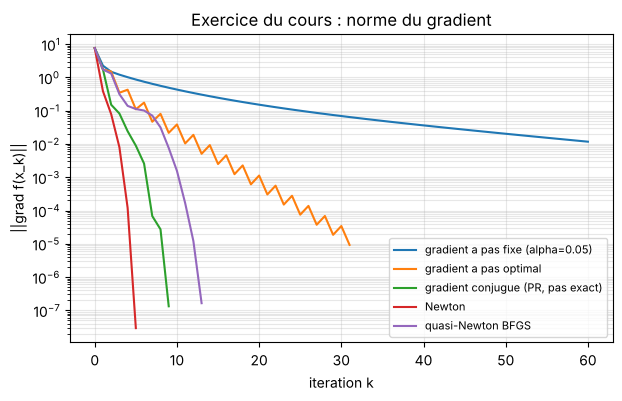

In [4]:
tracer_convergence(res, titre="Exercice du cours : norme du gradient", max_iter=60)
plt.show()

On retrouve les vitesses de convergence du cours : linéaire pour les deux méthodes de gradient, superlinéaire
pour BFGS, quadratique pour Newton (le nombre de chiffres exacts double à chaque itération à la fin).

## Exercice 1 — quadratique mal conditionnée

$f(x,y) = (x-2)^2 + 20(y+1)^2$ : minimum évident en $(2,-1)$ avec $f=0$.
$\nabla^2 f = \mathrm{diag}(2, 40)$, conditionnement $\kappa = 20$.

Avec le pas optimal, $\alpha_k$ minimise $\varphi(\alpha) = f(x_k - \alpha g_k)$, donc
$\varphi'(\alpha_k) = -\nabla f(x_{k+1})^\top g_k = 0$ : deux gradients successifs sont orthogonaux, d'où le zigzag.
Pour le pas fixe, la convergence exige $\alpha < 2/\lambda_{\max} = 2/40 = 0.05$.

In [5]:
e = exercice(1)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.04)          194  2.226470876e-13   9.44e-07        195/195/0  oui   (2, -1)
gradient a pas optimal                     17  1.039443399e-14   2.05e-07         883/18/0  oui   (2, -1)
gradient conjugue (PR, pas exact)           2  3.397888856e-17   5.21e-08          102/3/0  oui   (2, -1)
Newton                                      1  7.888609052e-31   1.78e-15            2/2/1  oui   (2, -1)
quasi-Newton BFGS                           8  6.972661587e-15   6.54e-07          10/10/0  oui   (2, -1)


In [6]:
r = res[1]
g = [e.probleme().grad(h[1]) for h in r.historique[:6]]
for k in range(5):
    cos = g[k+1] @ g[k] / (np.sqrt(g[k+1] @ g[k+1]) * np.sqrt(g[k] @ g[k]))
    print(f"cos(g_{k+1}, g_{k}) = {cos: .1e}")

cos(g_1, g_0) = -4.9e-09
cos(g_2, g_1) = -2.3e-09
cos(g_3, g_2) = -8.8e-09
cos(g_4, g_3) = -5.2e-10
cos(g_5, g_4) = -7.3e-08


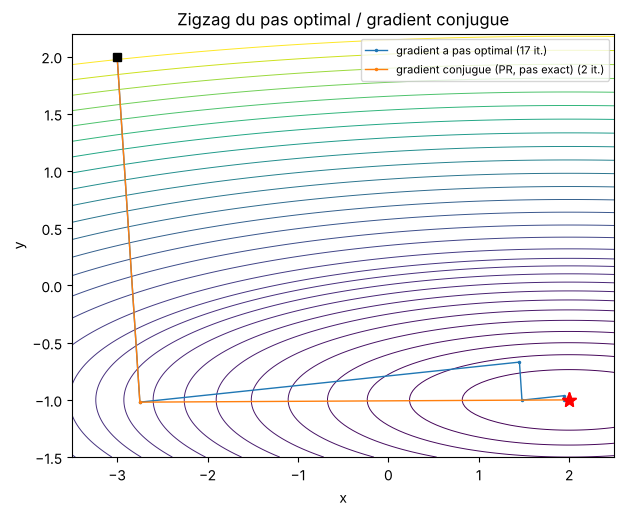

In [7]:
tracer_trajectoires(e.probleme(), [res[1], res[2]], cadre=(-3.5, 2.5, -1.5, 2.2),
                    titre="Zigzag du pas optimal / gradient conjugue")
plt.show()

In [8]:
for a in (0.01, 0.04, 0.049, 0.051):
    r = e.resoudre("pas_fixe", alpha=a, max_iter=20000)
    print(f"alpha = {a:<6} iterations = {r.iterations:<6} {r.message[:60]}")

alpha = 0.01   iterations = 798    convergence
alpha = 0.04   iterations = 194    convergence
alpha = 0.049  iterations = 456    convergence
alpha = 0.051  iterations = 374    divergence. alpha = 0.051 >= 2/lambda_max = 0.05 : prendre u


## Exercice 2 — fonction de Booth

$f(x,y) = (x+2y-7)^2 + (2x+y-5)^2 \ge 0$, et $f = 0$ si et seulement si
$x + 2y = 7$ et $2x + y = 5$, soit $(x,y) = (1,3)$ : minimum global.

$\nabla^2 f = \begin{pmatrix}10&8\\8&10\end{pmatrix}$ (constante, valeurs propres 2 et 18).
f est quadratique : Newton converge en 1 itération et le gradient conjugué avec pas exact en au plus 2.

In [9]:
e = exercice(2)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.05)          141  2.496994917e-13   9.99e-07        142/142/0  oui   (1, 3)
gradient a pas optimal                      9  6.809818526e-14   5.23e-07         466/10/0  oui   (1, 3)
gradient conjugue (PR, pas exact)           2  1.731135253e-16   7.89e-08          101/3/0  oui   (1, 3)
Newton                                      1  3.944304526e-30   7.11e-15            2/2/1  oui   (1, 3)
quasi-Newton BFGS                           6  2.964081548e-14   3.89e-07            7/7/0  oui   (1, 3)


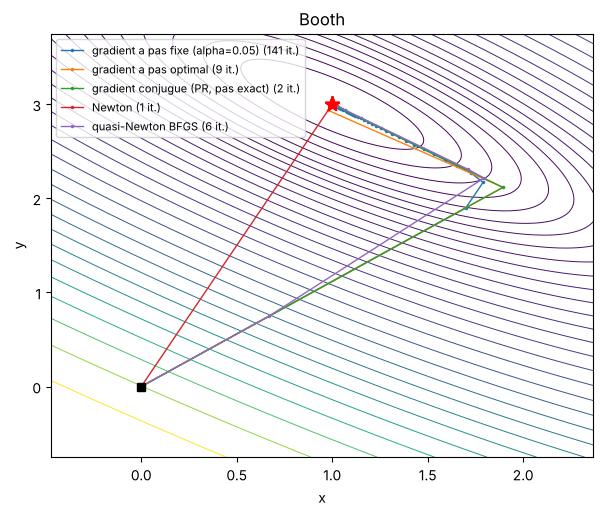

In [10]:
tracer_trajectoires(e.probleme(), res, titre="Booth")
plt.show()

## Exercice 3 — fonction de Beale

En $(3, \tfrac12)$ : $1.5 - 3 + 1.5 = 0$, $2.25 - 3 + 0.75 = 0$, $2.625 - 3 + 0.375 = 0$, donc $f(3,\tfrac12) = 0$.
Comme f est une somme de carrés, $f \ge 0$ et $(3, \tfrac12)$ est un minimum global.

In [11]:
e = exercice(3)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.01)         3845  1.651402117e-12   9.98e-07      3846/3846/0  oui   (3, 0.499999)
gradient a pas optimal                    223  1.359555492e-12   9.33e-07      11695/224/0  oui   (3, 0.499999)
gradient conjugue (PR, pas exact)           8   1.61671001e-20   1.26e-09          417/9/0  oui   (3, 0.5)
Newton                                      7  2.253128208e-18   5.71e-09            8/8/7  oui   (3, 0.5)
quasi-Newton BFGS                          16  3.184509231e-15   5.35e-07          17/17/0  oui   (3, 0.5)


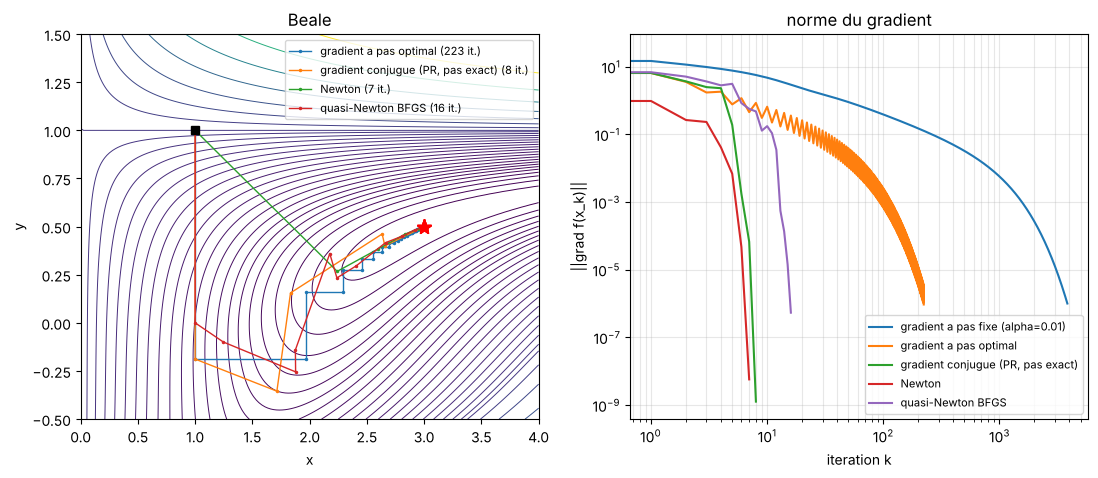

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
tracer_trajectoires(e.probleme(), res[1:], cadre=(0, 4, -0.5, 1.5), ax=ax[0], titre="Beale")
tracer_convergence(res, ax=ax[1], titre="norme du gradient")
ax[1].set_xscale("log")
plt.show()

Le pas fixe (alpha = 0.01) demande environ 3 800 itérations et le pas optimal plus de 200 : f est très plate dans
la direction de la vallée qui mène à $(3, 0.5)$. Newton (7) et le gradient conjugué (8) sont les plus rapides.

## Exercice 4 — localisation d'un entrepôt (problème de Weber)

$D(x,y) = \sum_i w_i \sqrt{(x-a_i)^2 + (y-b_i)^2}$.

a) Chaque terme est différentiable sauf au point $(a_i, b_i)$ (la norme n'est pas dérivable en 0) :
D n'est pas différentiable aux 4 clients. Ailleurs
$\nabla D = \sum_i w_i \dfrac{(x,y) - (a_i,b_i)}{\|(x,y) - (a_i,b_i)\|}$.
D est convexe (somme de normes), donc tout point critique est le minimum global.

b) Le barycentre $\frac{\sum w_i (a_i,b_i)}{\sum w_i} = (6.2,\ 4.1)$ minimise $\sum w_i \|\cdot\|^2$, pas $D$.

In [13]:
e = exercice(4)
res = e.comparer()
pb = e.probleme()
G = np.array([6.2, 4.1])
print(f"\nbarycentre (6.2, 4.1) : D = {pb.f(G):.4f} km")
print(f"entrepot optimal      : D = {res[3].f:.4f} km  en {np.round(res[3].x, 4)}")

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.1)           318      60.57126148   9.59e-07        319/319/0  oui   (7.84572, 5.45363)
gradient a pas optimal                     25      60.57126148   7.99e-07        1302/26/0  oui   (7.84572, 5.45363)
gradient conjugue (PR, pas exact)           6      60.57126148   8.92e-08          318/7/0  oui   (7.84572, 5.45363)
Newton                                      4      60.57126148   8.14e-08            5/5/4  oui   (7.84572, 5.45363)
quasi-Newton BFGS                           7      60.57126148   2.95e-08            8/8/0  oui   (7.84572, 5.45363)

barycentre (6.2, 4.1) : D = 61.7138 km
entrepot optimal      : D = 60.5713 km  en [7.8457 5.4536]


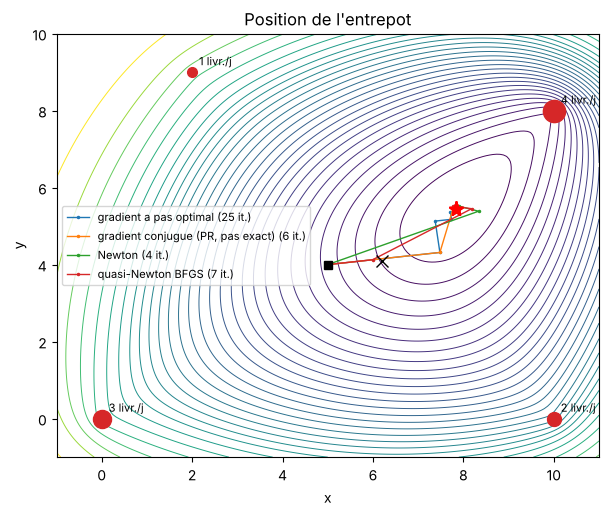

In [14]:
from exercices.exercice_4_entrepot_weber import CLIENTS
ax = tracer_trajectoires(pb, res[1:], cadre=(-1, 11, -1, 10), titre="Position de l'entrepot")
for a, b, w in CLIENTS:
    ax.plot(a, b, "o", color="tab:red", ms=4 + 3*w)
    ax.annotate(f"{w} livr./j", (a, b), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.plot(*G, "kx", ms=9)
plt.show()

Le point optimal $(7.846,\ 5.454)$ est tiré vers le client le plus important $(10, 8)$ ; il est différent
du barycentre, qui donne une distance totale plus grande. On a vérifié la solution par l'algorithme de Weiszfeld.

## Exercice 5 — régression logistique

Avec $z_i = w h_i + b$ et $\sigma(u) = 1/(1+e^{-u})$ :
$$\nabla L = -\sum_i y_i\,\sigma(-y_i z_i)\begin{pmatrix}h_i\\1\end{pmatrix}, \qquad
\nabla^2 L = \sum_i \sigma(z_i)\big(1-\sigma(z_i)\big)\begin{pmatrix}h_i\\1\end{pmatrix}\begin{pmatrix}h_i & 1\end{pmatrix}.$$
La hessienne est une somme de matrices semi-définies positives : L est convexe.
Les données ne sont pas séparables (h = 4 admis mais h = 5 et 7 recalés), donc le minimum existe.

In [15]:
e = exercice(5)
res = e.comparer()
w, b = res[3].x
print(f"\nw = {w:.6f}, b = {b:.6f}")
print(f"P(admis) > 0.5 a partir de h = -b/w = {-b/w:.2f} heures")

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.01)         7201      4.335111437   9.99e-07      7202/7202/0  oui   (0.676705, -3.72188)
gradient a pas optimal                    510      4.335111437   9.69e-07      26587/511/0  oui   (0.676705, -3.72188)
gradient conjugue (PR, pas exact)           6      4.335111437   2.27e-07          314/7/0  oui   (0.676706, -3.72188)
Newton                                      5      4.335111437   9.02e-10            6/6/5  oui   (0.676706, -3.72188)
quasi-Newton BFGS                          15      4.335111437   8.56e-08          18/18/0  oui   (0.676706, -3.72188)

w = 0.676706, b = -3.721882
P(admis) > 0.5 a partir de h = -b/w = 5.50 heures


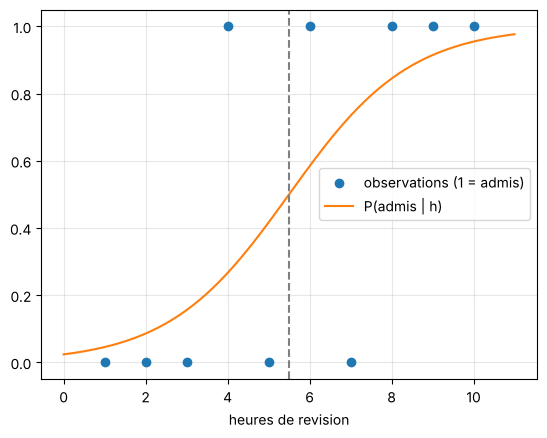

In [16]:
from exercices.exercice_5_regression_logistique import HEURES, REUSSITE
h = np.linspace(0, 11, 200)
plt.plot(HEURES, [(r + 1)/2 for r in REUSSITE], "o", label="observations (1 = admis)")
plt.plot(h, 1/(1 + np.exp(-(w*h + b))), label="P(admis | h)")
plt.axvline(-b/w, ls="--", c="gray"); plt.xlabel("heures de revision"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Exercice 6 — points critiques de $x^4 + y^4 + z^4 - 4xyz$

$\nabla f = 4(x^3 - yz,\ y^3 - xz,\ z^3 - xy)$. En multipliant les trois équations : $(xyz)^3 = (xyz)^2$,
donc $xyz \in \{0, 1\}$.
- $xyz = 0$ : si $x = 0$ alors $y^3 = 0$ et $z^3 = 0$ : l'origine.
- $xyz = 1$ : $x^4 = xyz = 1$, de même pour y et z, donc $|x|=|y|=|z|=1$ avec un produit égal à 1 :
  $(1,1,1)$, $(1,-1,-1)$, $(-1,1,-1)$, $(-1,-1,1)$, avec $f = -1$.

En $(1,1,1)$ : $\nabla^2 f = 12I - 4\begin{pmatrix}0&1&1\\1&0&1\\1&1&0\end{pmatrix}$, valeurs propres 4, 16, 16 : minimum.
À l'origine la hessienne est nulle ; $f(t,t,t) = 3t^4 - 4t^3 < 0 < f(-t,-t,-t)$ pour $t>0$ petit : ni min ni max.

In [17]:
e = exercice(6)
res = e.comparer()
print()
for m in ("newton_pur", "newton"):
    r = e.resoudre(m, x0=[0.1, 0.2, 0.3])
    print(f"{m:<11} depuis (0.1, 0.2, 0.3) -> x = {np.round(r.x, 4)}, f = {r.f:.4g} : {r.nature}")

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.02)          160               -1   9.68e-07        161/161/0  oui   (1, 1, 1)
gradient a pas optimal                     14               -1   3.15e-07         727/15/0  oui   (1, 1, 1)
gradient conjugue (PR, pas exact)           8               -1   7.62e-08          413/9/0  oui   (1, 1, 1)
Newton                                      7               -1   1.01e-09           18/8/7  oui   (1, 1, 1)
quasi-Newton BFGS                          13               -1   2.53e-07          14/14/0  oui   (1, 1, 1)

newton_pur  depuis (0.1, 0.2, 0.3) -> x = [0.    0.    0.006], f = 1.336e-09 : ATTENTION : point selle
newton      depuis (0.1, 0.2, 0.3) -> x = [1. 1. 1.], f = -1 : minimum local strict (hessienne definie positive)


Depuis $(0.1, 0.2, 0.3)$, Newton pur est attiré par le point critique de l'origine (la norme du gradient y devient
inférieure à la tolérance) : ce n'est pas un minimum. La version globalisée (hessienne rendue définie positive + Armijo)
va bien vers $(1,1,1)$. Une norme de gradient petite ne suffit pas : il faut vérifier la hessienne.

## Exercice 7 — fonction de Wood

Problème test classique en dimension 4 (Moré, Garbow, Hillstrom 1981), minimum $f=0$ en $(1,1,1,1)$,
départ $(-3,-1,-3,-1)$. Avec $\alpha = 0.001$ le pas fixe diverge dès la 2e itération (gradient énorme au départ),
on prend $\alpha = 0.0005$.

In [18]:
e = exercice(7)
res = e.comparer()

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.0005)      52401  6.945636565e-13   1.00e-06    52402/52402/0  oui   (1, 0.999999, 1, 1)
gradient a pas optimal                   8050  4.836226853e-13   9.98e-07    402276/8051/0  oui   (1, 1, 1, 0.999999)
gradient conjugue (PR, pas exact)          67  5.295263032e-14   2.77e-07        3396/68/0  oui   (1, 1, 1, 1)
Newton                                     38  1.233488629e-18   2.25e-08         52/39/38  oui   (1, 1, 1, 1)
quasi-Newton BFGS                          38  6.806832256e-18   7.35e-08          55/55/0  oui   (1, 1, 1, 1)


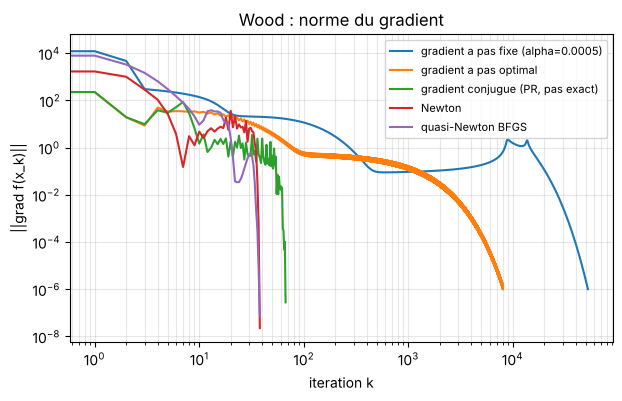

In [19]:
tracer_convergence(res, titre="Wood : norme du gradient")
plt.xscale("log")
plt.show()

Le pas fixe demande plus de 50 000 itérations, le pas optimal environ 8 000, contre 38 pour Newton et BFGS.
En nombre d'évaluations, BFGS est aussi économique que Newton sans jamais calculer de hessienne.

## Résoudre un autre exercice avec nos fonctions

Il suffit d'écrire f sous forme de chaîne (les variables sont détectées puis rangées : x, y, z ou x1, x2, ..., x10)
ou de donner une fonction Python. Exemple :

In [20]:
r = minimiser("(x - 1)**4 + (x - 2*y)**2 + z**2 - z*x", x0=[0, 2, 1], methode="newton")
print(r)
print()
comparer("(x - 1)**4 + (x - 2*y)**2 + z**2 - z*x", [0, 2, 1]);

Methode            : Newton
Converge           : oui
Iterations         : 7
x*                 : (1.5826866, 0.79134328, 0.79134328)
f(x*)              : -0.5109478934
||grad f(x*)||     : 1.096e-07
Evaluations f/g/H  : 10 / 8 / 7
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)

methode                                  iter            f(x*)   ||grad||       eval f/g/H   ok   x*
gradient a pas fixe (alpha=0.0622782)     141    -0.5109478934   9.07e-07        142/142/0  oui   (1.58269, 0.791343, 0.791343)
gradient a pas optimal                     41    -0.5109478934   6.63e-07        2150/42/0  oui   (1.58269, 0.791343, 0.791343)
gradient conjugue (PR, pas exact)           9    -0.5109478934   6.95e-07         473/10/0  oui   (1.58269, 0.791343, 0.791343)
Newton                                      7    -0.5109478934   1.10e-07           10/8/7  oui   (1.58269, 0.791343, 0.791343)
quasi-Newton BFGS                          15    -0

In [21]:
# avec une fonction python (gradient exact facultatif, sinon differences finies)
def f(X):
    a, b = X
    return (a - 1)**2 + 5*(b - a**2)**2

print(minimiser(f, [-1, 2], methode="bfgs"))

Methode            : quasi-Newton BFGS
Converge           : oui
Iterations         : 20
x*                 : (1, 1)
f(x*)              : 1.64901602e-19
||grad f(x*)||     : 5.819e-10
Evaluations f/g/H  : 140 / 28 / 0
Message            : convergence
Nature du point    : minimum local strict (hessienne definie positive)


En ligne de commande (depuis le dossier principal, sans ouvrir le notebook) :

```bash
python newton.py                                   # Newton sur l'exercice du cours
python newton.py "x**2 + 3*y**2 - x*y" 1 1         # Newton sur une autre fonction
python exercices/exercice_3_xxx.py                 # un exercice, toutes les méthodes
python exercices/exercice_3_xxx.py newton          # un exercice, une méthode
python resoudre.py -f "x**2 + 3*y**2 - x*y" --x0 1 1
python verifier.py                                 # tous les exercices, toutes les méthodes
```

## Bilan

Nombre d'itérations de chaque méthode sur chaque exercice :

In [22]:
import verifier
verifier.main()

Nombre d'iterations   * = resultat faux ou non converge
                      ~ = echec attendu (limite de la methode, voir l'enonce)

exercice                                        pas fixe    pas opt. grad. conj.      Newton        BFGS
 0 Exercice du cours                                197          31           9           5          13 
 1 Quadratique mal conditionnee (zigzag)            194          17           2           1           8 
 2 Fonction de Booth                                141           9           2           1           6 


 3 Fonction de Beale                               3845         223           8           7          16 
 4 Localisation d'un entrepot (probleme de W        318          25           6           4           7 


 5 Regression logistique                           7201         510           6           5          15 
 6 Points critiques de x^4 + y^4 + z^4 - 4xy        160          14           8           7          13 


 7 Fonction de Wood (dimension 4)                 52401        8050          67          38          38 

0 echec(s) - 4.3 s
